In [ ]:
import sys
import os

sys.path.append(os.path.abspath('..'))

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from src.dataset import get_dataloaders

model = tf.keras.models.load_model('../models/unet_best_model.keras')
print("Model Loaded Successfully!")

Model Loaded Successfully!


In [3]:
_, val_ds, class_names = get_dataloaders(
    '../data/images/', '../data/annotations/trimaps/', 
    batch_size=8, target_size=(128, 128)
)

images, targets = next(iter(val_ds))
true_masks, true_labels = targets
print("Got a batch.")

Got a batch.


W0000 00:00:1777831524.202661 2538538 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step


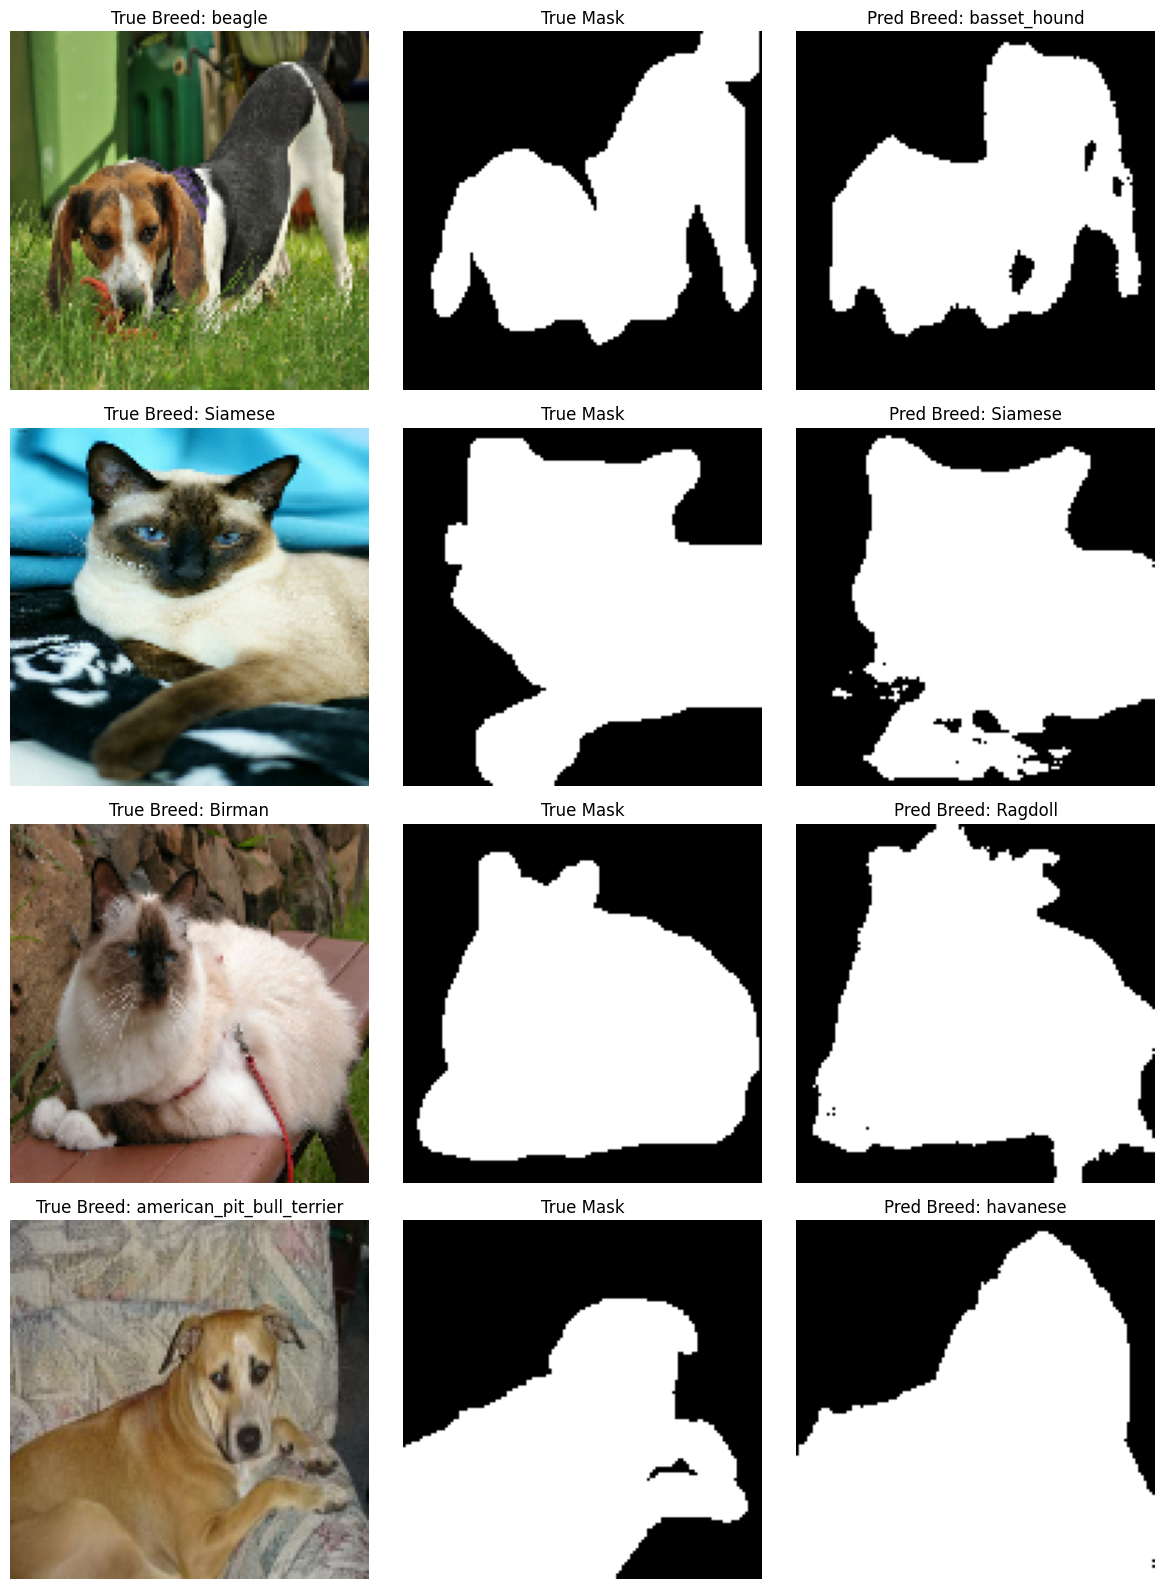

In [4]:
pred_masks, pred_labels = model.predict(images)

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for i in range(4):
    axes[i, 0].imshow(images[i].numpy())
    true_class_name = class_names[true_labels[i].numpy()]
    axes[i, 0].set_title(f"True Breed: {true_class_name}")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(true_masks[i].numpy(), cmap='gray')
    axes[i, 1].set_title("True Mask")
    axes[i, 1].axis('off')

    pred_mask_binary = (pred_masks[i] > 0.5).astype(np.float32)
    axes[i, 2].imshow(pred_mask_binary, cmap='gray')

    pred_class_idx = np.argmax(pred_labels[i])
    pred_class_name = class_names[pred_class_idx]
    axes[i, 2].set_title(f"Pred Breed: {pred_class_name}")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

Loading Attention U-Net...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step


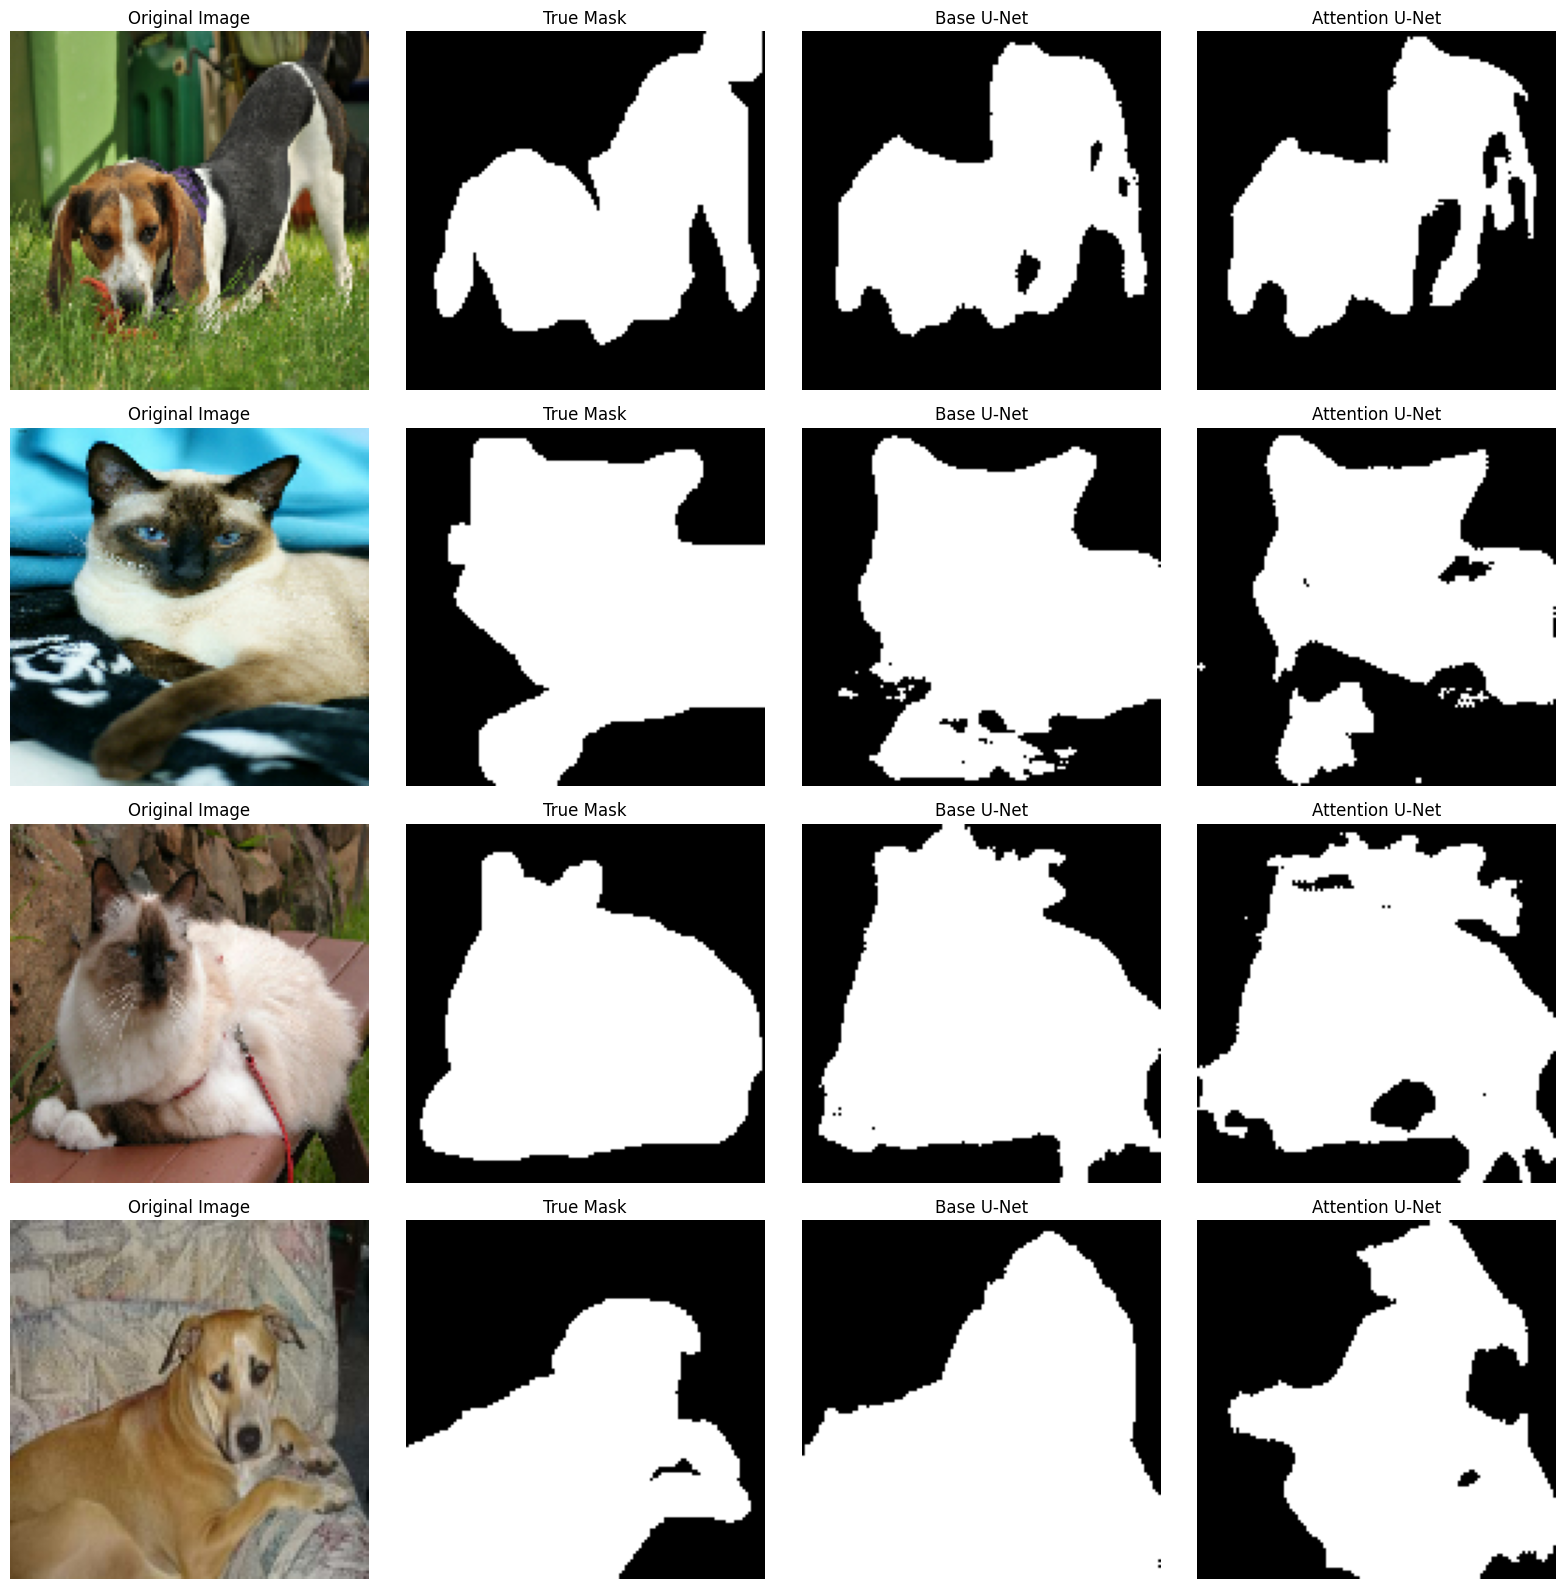

In [5]:
print("Loading Attention U-Net...")
attention_model = tf.keras.models.load_model('../models/attention_unet_best_model.keras')

att_pred_masks, att_pred_labels = attention_model.predict(images)

fig, axes = plt.subplots(4, 4, figsize=(16, 16))

for i in range(4):

    axes[i, 0].imshow(images[i].numpy())
    axes[i, 0].set_title("Original Image")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(true_masks[i].numpy(), cmap='gray')
    axes[i, 1].set_title("True Mask")
    axes[i, 1].axis('off')


    base_mask_binary = (pred_masks[i] > 0.5).astype(np.float32)
    axes[i, 2].imshow(base_mask_binary, cmap='gray')
    axes[i, 2].set_title("Base U-Net")
    axes[i, 2].axis('off')
    
    att_mask_binary = (att_pred_masks[i] > 0.5).astype(np.float32)
    axes[i, 3].imshow(att_mask_binary, cmap='gray')
    axes[i, 3].set_title("Attention U-Net")
    axes[i, 3].axis('off')

plt.tight_layout()
plt.show()